# 3. Several defects close together, and which configurations are equivalent

Put any list of dislocations and disclinations on the lattice of Notebook 1, as close as you like, look at the lattice, and decide which configurations are the same.

**Equivalence: total charge + core graph.**
1. **Total charge.** Walk once round all the defects at once. The holonomy of that big loop is the product of the individual holonomies; its class (as in Notebook 2) is the total charge. Example: on the square lattice, +90 at a site c1 and -90 at the neighbouring face centre c2 compose to a pure translation: (R90, (I-R90)c1)(R-90, (I-R-90)c2) = (I, (R90 - I)c2) (c1 = 0), so b = (I - R90)c2 = (1, 0) (up to the class): together they are **one unit dislocation**.
2. **Core graph.** The sites whose neighbourhood (out to a few bonds) differs from the perfect lattice, with the bonds between them: compared as graphs (isomorphism), not as pictures. In the example, the +90 site has 3 bonds and the -90 face is a pentagon: exactly the core of the unit dislocation. So the pair **is** a dislocation.
Two configurations are equivalent when both agree. `equivalent_single(config)` finds the single defect with the same total charge and says whether the cores match.

**Status.** Total charge: read from the built graph (computational evidence; the algebra is proved). Core comparison: exact graph isomorphism of the core balls. "No match" for a dislocation means none among the cores found by scanning cut positions (`grid`), not a proof.

In [1]:
# Setup: find the papertilling package (it sits in the folder above this notebook) and check what it needs.
import sys, pathlib, importlib.util
for _p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_p / "papertilling" / "__init__.py").exists():
        sys.path.insert(0, str(_p)); break
_kernel = "uv pip install --python '" + sys.executable + "' "
if importlib.util.find_spec("papertilling") is None:
    raise ImportError("papertilling not found. Keep this notebook inside the papertilling/notebooks folder, or install the "
                      "package into this kernel:  " + _kernel + "-e <path to the papertilling folder>")
_missing = [m for m in ("numpy", "scipy", "networkx", "matplotlib", "spglib") if importlib.util.find_spec(m) is None]
if _missing:
    raise ImportError("this kernel lacks " + ", ".join(_missing) + ". Install with:  " + _kernel + " ".join(_missing)
                      + "   (or run  %pip install " + " ".join(_missing) + "  in a cell)")
import papertilling
print("papertilling", papertilling.__version__, "| Python", sys.version.split()[0], "| numba:", importlib.util.find_spec("numba") is not None,
      "| sliders:", importlib.util.find_spec("ipywidgets") is not None)

papertilling 0.2.0 | Python 3.12.16 | numba: True | sliders: True


In [2]:
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning)
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from papertilling.defects.catalogue import DefectCatalogue
from papertilling.defects.build import build
from papertilling.defects.config import equivalent_single, compare, classify

## 0. Control: a known example on the square lattice

+90 at the site (0, 0) and -90 at the face centre (1/2, 1/2) of the square lattice.

**How the crystals are drawn.** `build` first places the sites by cutting and regluing the plane once per defect (the "raw" picture, `picture="raw"`). With two or more disclinations the raw picture is not a faithful drawing: each disclination stretches the angles around its own centre, and for a +alpha/-alpha pair the two stretches do not cancel, so the far field covers more than 360 deg and folds over itself along the cut (for +-90 deg it covers about 384 deg). The graph (who is bonded to whom) is right; only the positions are wrong. The default `picture="relaxed"` therefore lets the bonds relax like springs, and if the result still has crossing bonds or folded faces it redraws the crystal: first only around the bad region, and if needed the whole crystal with its rim pinned to a circle and each site placed at the average of its neighbours (by Tutte's theorem that drawing has no crossing bonds when the crystal's graph is 3-connected, which most crystals are). If no stage gives a clean picture, the least bad one is kept and the plot title says how many crossings or overlaps remain. `c.defect.info["drawing"]` says which stage was used.

A configuration whose Frank angles do not add up to 0 cannot have an undistorted far field in the plane: a net +alpha makes the plane a cone, and the drawing must squeeze it (or, for a net negative angle, crowd it). Only net-zero configurations look like the perfect lattice far away.

V = 522, E = 991, F = 471 (with the outside): V - E + F = 2; frames consistent: True
total Frank angle +0.000 deg (requested sum +0)
total charge: dislocation [b] = P+ orbit of [1.0, 0.0] (|b| = 1.0000); equals the single defect dislocation b = [1.0, 0.0]
  core: disclination +90 deg on a site with 3 bonds; coordination of its sites [3]
  core: disclination -90 deg on a 5-ring; coordination of its sites [3, 4, 4, 4, 4]


{'same_charge': True, 'same_charge_up_to_mirror': True, 'same_core': True}


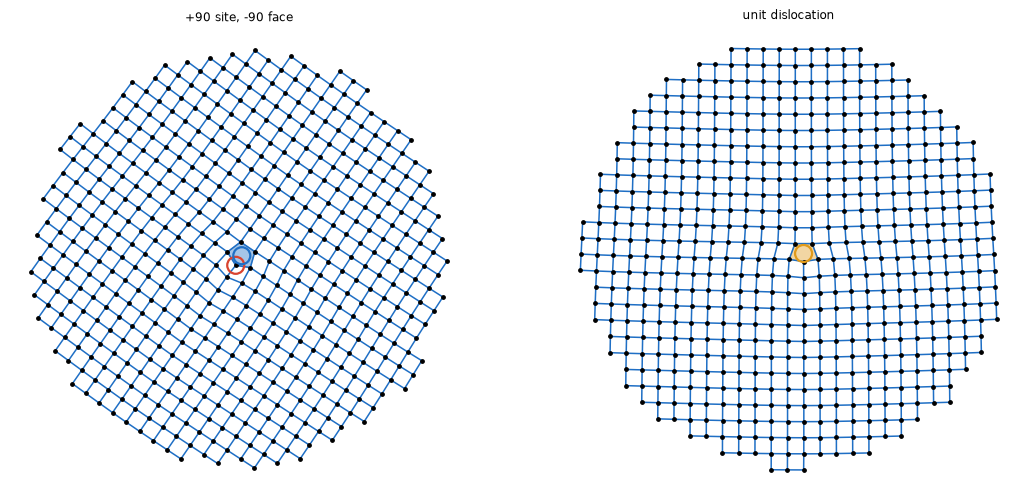

In [3]:
sq = "square"
pair = build(sq, dict(kind="disclination", angle=90, at=(0, 0)), dict(kind="disclination", angle=-90, at=(0.5, 0.5)))
pair.inspect()
single = build(sq, dict(kind="dislocation", b=(1, 0), at=(0.371, 0.413)))
print({k: v for k, v in compare(pair, single).items() if k != "details"})
fig, axs = plt.subplots(1, 2, figsize=(13, 6.5))
pair.plot(ax=axs[0], title="+90 site, -90 face"); single.plot(ax=axs[1], title="unit dislocation")
plt.show()

## 1. Your lattice and its defect classes

In [4]:
# LATTICE: paste a line printed by Notebook 1 (L.code()), or take entry PICK of a group's list.
from papertilling.lattice import load_catalogue, Lattice
L = load_catalogue()["p4g"].lattices[0]        # p4g #1 (points-only rule: the Shastry-Sutherland network)
# L = Lattice.from_recipe(dict(group="p4m", sites=[(0, 0)], bonds=[((0, 0), (1, 0))], a=1))   # square lattice
# from papertilling import named; L = named("Kagomé")                                        # a named lattice
print(L)

Lattice(p4g, rank (1, 2, 4, 10): 1 site orbit(s) ['4c ..m'], 2 bond orbit(s), 4 sites and 10 bonds per primitive cell)


In [5]:
cat = DefectCatalogue(L)
for c in cat.centre_classes:
    print(f"{c['label']:8s} order {c['order']}  point {np.round(c['point'], 4).tolist()}  {c['location']}  angles {c['angles']}")
for t in cat.dislocations:
    print(t["id"], "b =", np.round(t["b"], 4).tolist(), "|b| =", round(t["length"], 4))

2a(i)    order 4  point [0.0, 0.0]  face centre  angles [-180.0, -90.0, 90.0, 180.0]
2a(ii)   order 4  point [0.5, 0.5]  face centre  angles [-180.0, -90.0, 90.0, 180.0]
2b       order 2  point [0.0, 0.5]  bond midpoint  angles [-180.0, 180.0]
T1 b = [1.0, 0.0] |b| = 1.0
T2 b = [1.0, 1.0] |b| = 1.4142


## 2. Build configurations

A defect is a dict:
* `dict(kind="disclination", angle=90, at=(x, y))`: `at` must be a rotation centre that allows the angle (or add `snap=True` to `build` to move it to the nearest one);
* `dict(kind="dislocation", b=(bx, by), at=(x, y))`: `b` a lattice vector, `at` the end of the cut (any point; the core changes as it moves inside a cell).

Points are Cartesian, in the frame of the plot. `centre(label, shift)` below gives the centre of a class moved by a lattice vector `shift` (in cells).

highest-order centres: ['2a(i)', '2a(ii)'] angle 90.0


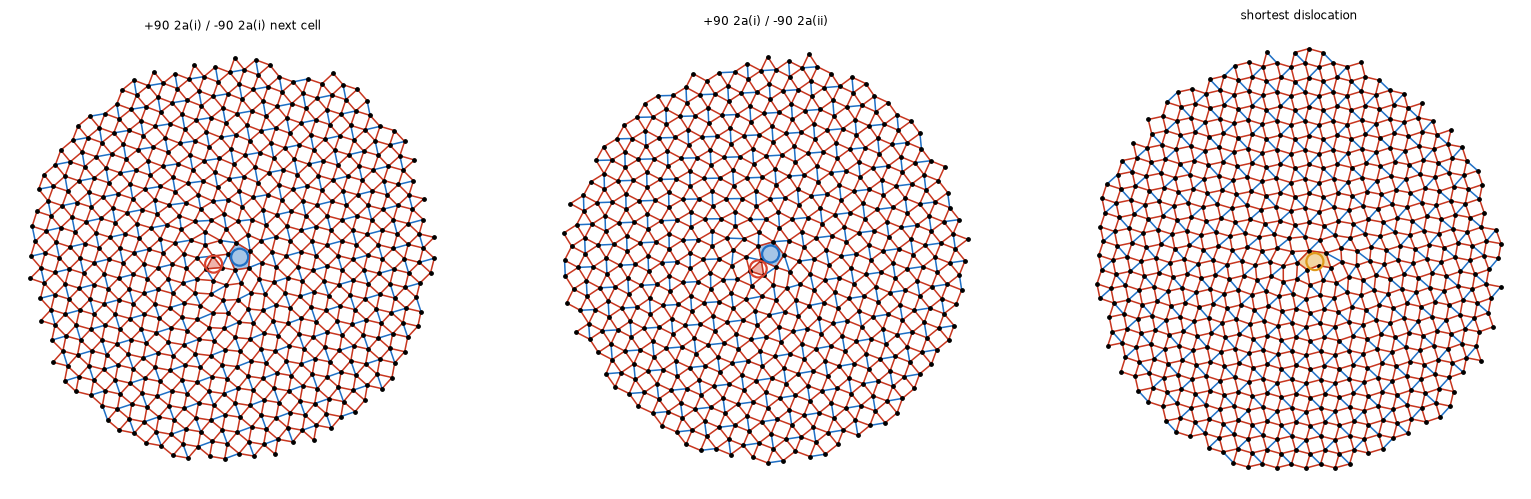

In [6]:
A = cat.cell.A
def centre(label, shift=(0, 0)):
    c = next(c for c in cat.centre_classes if c["label"] == label)
    return c["point"] + A @ np.array(shift, float)

top = max(c["order"] for c in cat.centre_classes)
alpha = 360 / top
labels = [c["label"] for c in cat.centre_classes if c["order"] == top]
print("highest-order centres:", labels, "angle", alpha)

configs = {
    f"+{alpha:g} {labels[0]} / -{alpha:g} {labels[0]} next cell": [dict(kind="disclination", angle=alpha, at=centre(labels[0])),
                                                                  dict(kind="disclination", angle=-alpha, at=centre(labels[0], (1, 0)))],
    f"+{alpha:g} {labels[0]} / -{alpha:g} {labels[-1]}": [dict(kind="disclination", angle=alpha, at=centre(labels[0])),
                                                          dict(kind="disclination", angle=-alpha, at=centre(labels[-1]))],
    "shortest dislocation": [dict(kind="dislocation", b=cat.dislocations[0]["b"], at=A @ np.array([0.371, 0.413]))],
}
built = {name: build(L, *specs) for name, specs in configs.items()}
fig, axs = plt.subplots(1, len(built), figsize=(6.5 * len(built), 6.5))
for ax, (name, c) in zip(np.atleast_1d(axs), built.items()):
    c.plot(ax=ax, title=name)
plt.show()

In [7]:
for name, c in built.items():
    print("==", name); c.inspect()

== +90 2a(i) / -90 2a(i) next cell


V = 623, E = 1485, F = 864 (with the outside): V - E + F = 2; frames consistent: True
total Frank angle -0.000 deg (requested sum +0)
total charge: dislocation [b] = P+ orbit of [1.0, 1.0] (|b| = 1.4142); equals the single defect dislocation b = [1.0, -1.0]
  core: disclination +90 deg on a 3-ring; coordination of its sites [5, 5, 5]
  core: disclination -90 deg on a 5-ring; coordination of its sites [5, 5, 5, 5, 5]
== +90 2a(i) / -90 2a(ii)
V = 588, E = 1399, F = 813 (with the outside): V - E + F = 2; frames consistent: True
total Frank angle -0.000 deg (requested sum +0)
total charge: dislocation [b] = P+ orbit of [1.0, 0.0] (|b| = 1.0000); equals the single defect dislocation b = [1.0, 0.0]
  core: disclination +90 deg on a 3-ring; coordination of its sites [5, 5, 5]
  core: disclination -90 deg on a 5-ring; coordination of its sites [5, 5, 5, 5, 5]
== shortest dislocation


V = 674, E = 1606, F = 934 (with the outside): V - E + F = 2; frames consistent: True
total Frank angle -0.000 deg (requested sum +0)
total charge: dislocation [b] = P+ orbit of [1.0, 0.0] (|b| = 1.0000); equals the single defect dislocation b = [1.0, 0.0]
  core: dislocation b = [1.0, -0.0] on a 6-ring; coordination of its sites [4, 3, 5, 5, 5, 5]


## 3. Which are equivalent?

`classify` groups the configurations by total charge and core graph. `equivalent_single` compares one configuration with the single defect of the same total charge (for a dislocation it scans cut positions: `grid`).

In [8]:
labels_eq = classify(list(built.values()), names=list(built.keys()))

configuration                    class  core (nodes, bonds)  total charge
+90 2a(i) / -90 2a(i) next cell  A      (54, 113)            dislocation [b] = P+ orbit of [1.0, 1.0] (|b| = 1.4142)
+90 2a(i) / -90 2a(ii)           B      (50, 104)            dislocation [b] = P+ orbit of [1.0, 0.0] (|b| = 1.0000)
shortest dislocation             C      (55, 115)            dislocation [b] = P+ orbit of [1.0, 0.0] (|b| = 1.0000)


**Reading the two answers.** One total charge (one dislocation class) can have **several cores**: the same Burgers vector can sit on different rings, depending on where the cut ends inside the cell and on which bonds close the core. So two configurations can have the same charge but different cores (different classes in the table above), and still **each** be equivalent to *a* single dislocation of that charge: `equivalent_single` says which of the single dislocation's cores it matches. A "Volterra core" comes from cut and reglue alone; a "completion core" also has bonds added between under-coordinated core sites, without crossings and without exceeding the perfect coordination. Whether completion cores count as the same defect is your call; the verdict says which kind matched.

In [9]:
for name, c in built.items():
    r = equivalent_single(c, grid=2)
    print(f"{name:40s} -> {r['verdict']}")

+90 2a(i) / -90 2a(i) next cell          -> no match among 124 distinct cores scanned (grid=2, 24 Volterra builds, completions capped 6 times, 0 skipped at the rim); a larger grid may find more cores


+90 2a(i) / -90 2a(ii)                   -> equivalent to the single defect (core: completion core 7)
shortest dislocation                     -> equivalent to the single defect (core: its own core (the configuration is one dislocation; its cut end is not among the scanned ones))


### See the cores

`equivalent_single(c, show=True)` draws the configuration's own core (first panel) next to every core of the single dislocation with the same charge: **Volterra cores** (cut and reglue only; the orange ring is the face that is not in the perfect lattice, red circles mark sites that lost a bond) in one row, and, when they exist, **completion cores** (a Volterra core healed by extra bonds, drawn as dashed magenta lines) in the next. The core that matches the configuration is framed in green. When the match is a completion core, the Volterra cores are always shown too, so you can see what was healed; at most 5 completion cores are drawn when there is a match (`r["gallery"]` holds them all).

The list of cores comes from a finite scan of cut positions (`grid`): a larger grid can find more cores, and the numbering ("completion core 7") belongs to that scan. The ring sizes in a title belong to the build that first reached that core; the same core can be reached with an extra perfect-size ring.

total charge: dislocation [b] = P+ orbit of [1.0, 0.0] (|b| = 1.0000)
        Volterra core 1 rings (6,), bipartite False
        Volterra core 2 rings (7,), bipartite False
        Volterra core 3 rings (8,), bipartite False
        Volterra core 4 rings (10,), bipartite False
        Volterra core 5 rings (10,), bipartite False
        Volterra core 6 rings (11,), bipartite False
  MATCH completion core 7 rings (3, 3, 3, 4, 5), bipartite False
        completion core 8 rings (3, 3, 4, 6), bipartite False
        completion core 9 rings (3, 3, 4, 6), bipartite False
        completion core 10 rings (3, 3, 4, 6), bipartite False
        completion core 11 rings (3, 3, 5, 5), bipartite False
        completion core 12 rings (3, 3, 5, 5), bipartite False
        completion core 13 rings (3, 4, 4, 5), bipartite False
        completion core 14 rings (3, 4, 4, 5), bipartite False
        completion core 15 rings (3, 4, 4, 5), bipartite False
        completion core 16 rings (3, 4, 4, 5), b

(figure: 6 Volterra core(s) and 5 of 71 completion core(s); res['gallery'] has them all, cores.plot_core_gallery draws any of them)


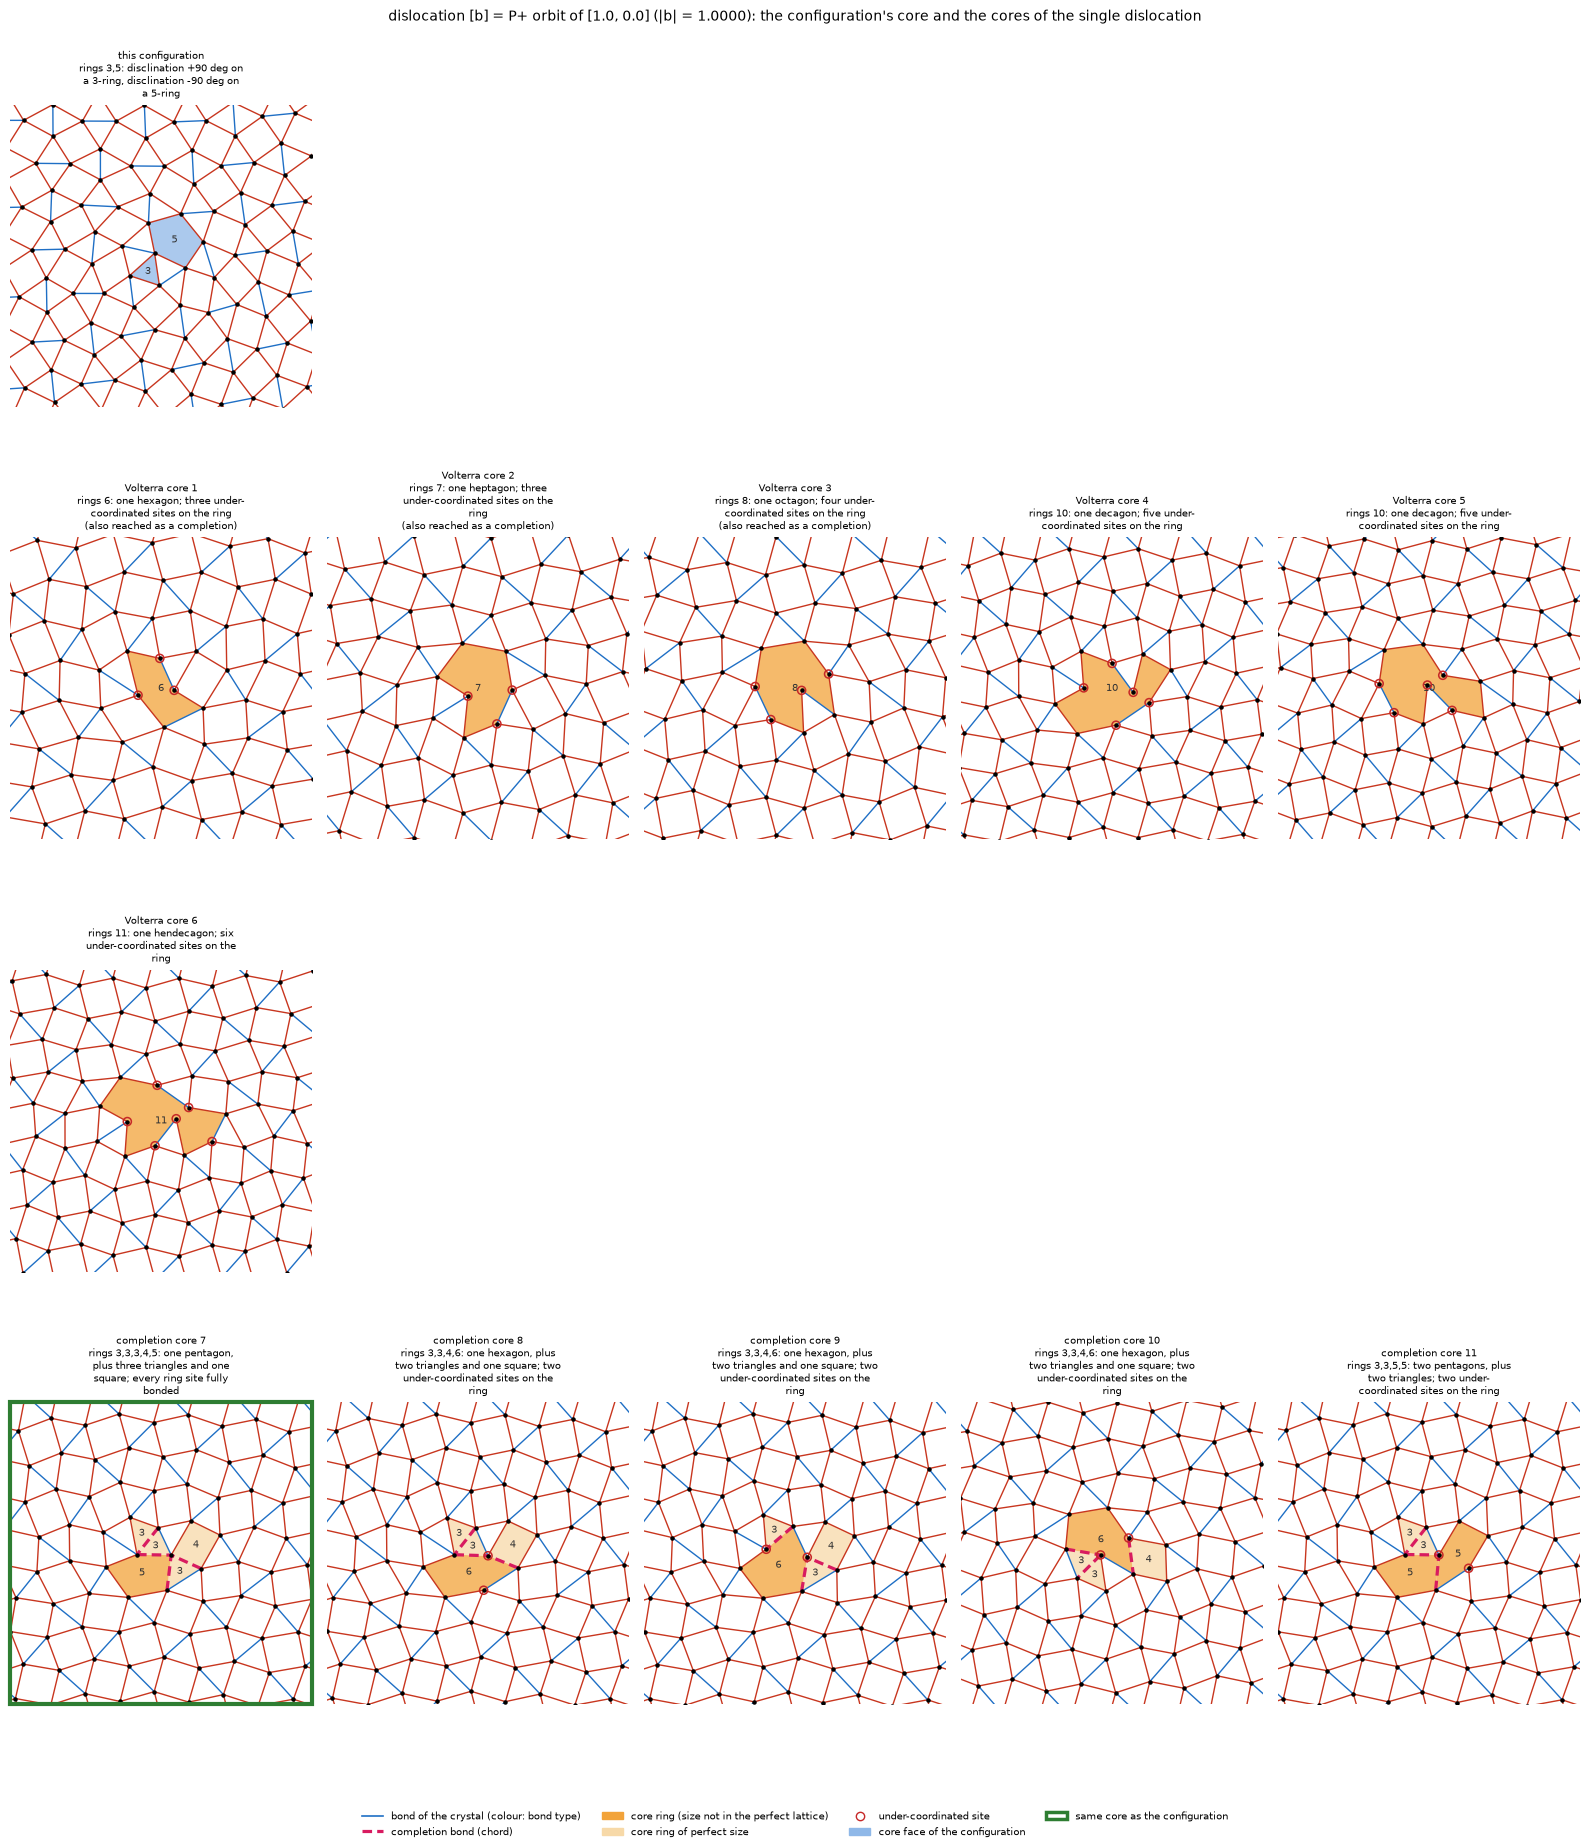

In [10]:
pair = built[f"+{alpha:g} {labels[0]} / -{alpha:g} {labels[-1]}"]
r = equivalent_single(pair, grid=2, show=True)

## 4. Your own configuration

Edit the list and run. `picture="relaxed"` (the default) gives a faithful drawing; `picture="raw"` the unrelaxed cut-and-reglue positions (faster; with several disclinations they overlap along the cuts). The graph is the same in both.

V = 724, E = 1724, F = 1002 (with the outside): V - E + F = 2; frames consistent: True
total Frank angle -0.000 deg (requested sum +0)
total charge: dislocation [b] = P+ orbit of [3.0, 0.0] (|b| = 3.0000); equals the single defect dislocation b = [0.0, -3.0]
  core: disclination +90 deg on a 3-ring; coordination of its sites [5, 5, 5]
  core: disclination -90 deg on a 5-ring; coordination of its sites [5, 5, 5, 5, 5]


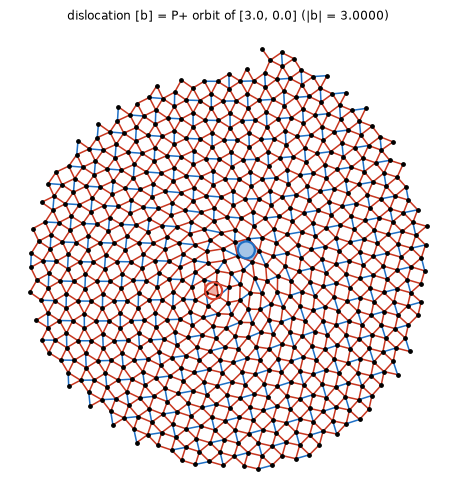

In [11]:
mine = build(L,
             dict(kind="disclination", angle=alpha, at=centre(labels[0])),
             dict(kind="disclination", angle=-alpha, at=centre(labels[-1], (1, 1))),
             picture="relaxed")
mine.inspect()
mine.plot(); plt.show()